In [1]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, append = True)
import time

import matplotlib.pyplot as plt
import matplotlib.ticker as tck
import numpy as np 

from fisher_lg.State import State_Evo
from fisher_lg.Models import (plot_lattice,
    KondoChain, KondoModel, AndersonImpurityModel, AndersonImpurityModel_Bulk, TFIsingChain)
import fisher_lg.tools as tls

from tenpy.models.lattice import Chain, Kagome, Triangular, Square



 [======================>.................]  55.17% 

final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=5.79e-04
final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=8.76e-05
final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=1.17e-04
final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=1.26e-04
final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=1.36e-04


 [========================>...............]  62.07% 

final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=1.98e-05


 [==========================>.............]  65.52% 

...

 [===============================>........]  79.31% 

final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=1.00e-05


 [=================================>......]  82.76% 

final DMRG state not in canonical form up to norm_tol=1.00e-05: norm_err=3.83e-05


 [========================================] 100.00% 


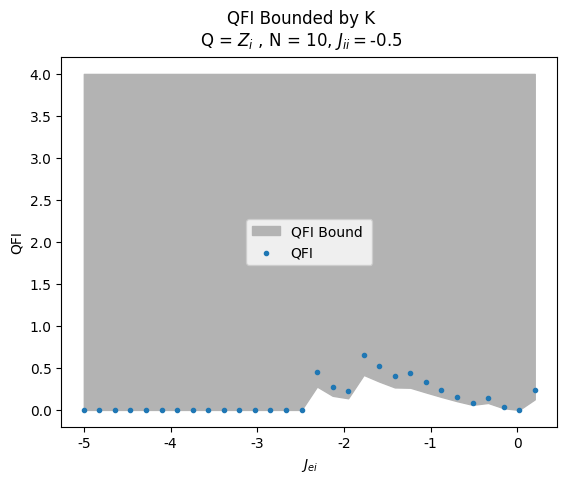

In [ ]:
L = 5
chi_max = int( min(8 ** (L/2), 400))
op = 'Sigmazi'
op_sum = False
num_points1 = 30
t_end = .5
dt = 0.01
j_ii = -.5

extra_params = {
    'mixer': True,  # setting this to True helps to escape local minima
    'max_E_err': 1.e-8,
    'max_sweeps'  : 30,
    'max_trunc_err' : 1e-5,
    'trunc_params': {
        'chi_max': chi_max,
        'svd_min': 1.e-10,
        'trunc_cut': 1e-6
    },
    'verbose': False,
    'combine': True,
    'N_times' : 2,  #Only even N_times are used for K,
    'dt': dt,'N_steps': 1,
    'order': 2,
    'start_time' : 0  ,
    't_max' : t_end,  #only an option for calculating the maximum of the LG correlator
}


theta_range1 = np.linspace(-5, .2, num_points1)

fig, ax = plt.subplots(1)
bar = tls.ProgressBar(min_value = theta_range1[0], max_value = theta_range1[-1])
            
LG_bound = []
QFI_lst =[]
for theta in theta_range1:
    model_params = {
    'J_ei':  theta , 'J_ii': j_ii,  #J_ei =1   J_ii pm,  J_ei=-1   J_ii pm
    't' : 1.0,
    'L': L,
    'model_type' : "Kondo",
    'conserve' : 'Sz',
    'symmetry_breaking_field' : 1.e-6} #conserve = None when not using from_dmrg_search_Sz

    psi_c = State_Evo.from_dmrg_search_Sz(model_params, extra_params, scan_Sz_with_Spi= True)
    t_max, LG_max , qfi = psi_c.calculate_LG_bound(op, op_sum = op_sum, return_QFI= True)
    LG_bound += [LG_max]
    QFI_lst += [qfi]
    bar.update(theta)
    

ax.fill_between(theta_range1, LG_bound, 4 ,  color = '.7', label = "QFI Bound "  )
ax.scatter(theta_range1, QFI_lst, marker = '.', label = "QFI", zorder = 3)


fig.suptitle("QFI Bounded by K\nQ = $Z_i$ , N = " + str(L) + ", $J_{ii}= $" + str(j_ei))
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("$J_{ei}$")
ax.set(ylabel = "QFI")
#plt.ylim((0.9,1.6))
plt.legend()

plt.show()

In [9]:
fig.savefig("C:\\Users\\ianro\\Documents\\Research\\Quantum_Metrology_AKLT\\Plots\\Kondo\\Kondo_L8_Jei-1_Zi_QFI_Bound.png")

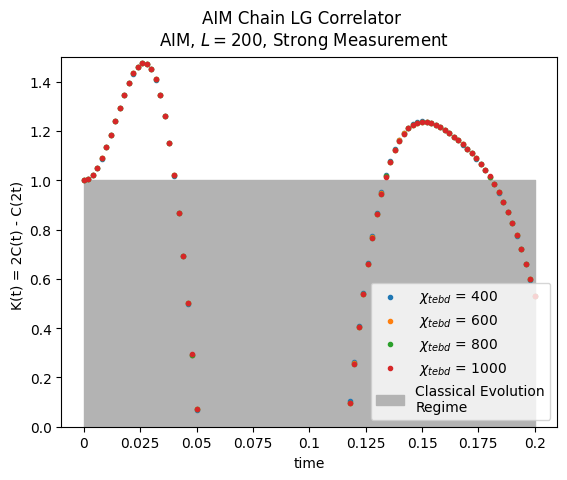

In [5]:
fig, ax = plt.subplots(1)
chi_max = 6000
Lx = 4
Ly = 3
Jii = -.2
Jei = -.1
U = 1.
V = 1/np.sqrt(10)
l = 200
h = 1e-7
#dt = .1
#chi_tebd = 300
#l = 200

param_list = [400, 600, 800, 1000]

for chi_tebd in param_list: 
    #out_filename = "L" + str(l) + "_U" + str(u) + "_V" + str(np.round(V,2)) + "_chi" + str(chi_max) + "_tebdChi" + str(chi_tebd) + "_cut" + str(100.) + "x1e_10_LGdata_TRI.npy"
    #out_filename = "Lx" + str(int(lx)) + "Ly" + str(int(Ly)) + "_U" + str(U) + "_V" + str(np.round(V,2)) + "_chi" + str(int(chi_max)) + "_tebdChi" + str(int(chi_tebd)) + "_cut" + str(1e10 * 1e-8) + "x1e_10_dt_"+str(dt)+"_LGdata.npy"
    out_filename = "Lx" + str(int(Lx)) + "Ly" + str(int(Ly)) + "_Jii" + str(Jii) + "_Jei" + str(Jei)+ "_h" +str(h* 1e7) + "em7_chi" + str(chi_max) + "_tebdChi" + str(int(chi_tebd)) + "_cut" + str(1e10 * 1e-8) + "x1em10_site" + str(6) + "Triangle.npy" 
    
    times, LG_b, Kt = np.load('..\\data\\LG_data\\' + out_filename, allow_pickle= True)
    ax.scatter(times, Kt, marker = '.', label= " $\\chi_{tebd}$ = " + str(chi_tebd) , zorder= 3)


ax.fill_between(times,-3, 1 ,  color = '.7', label = "Classical Evolution\nRegime"  )

fig.suptitle("AIM Chain LG Correlator\n AIM, $L = 200$, Strong Measurement")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("time")
ax.set(ylabel = "K(t) = 2C(t) - C(2t) ")
ax.set_ylim([0,1.5])
plt.legend()

plt.show()

In [ ]:
#estimator for lg peak
for i in [4., 6., 8., 10., 20.]:

    psi = tls.load_state('..\\data\\psi_data\\L200_U'+str(i)+'_V0.32_chi3000_cut100.0x1e10.pkl')
    phi = psi.apply_Q_MPO('Sz', site = 0, op_sum = 0)
    q2 = phi.overlap(phi)
    q = np.real(phi.overlap(psi))
    qhq = psi.model.H_MPO.expectation_value(phi) * q2
    h = psi.model.H_MPO.expectation_value(psi)
    hpsi = psi.copy()
    psi.model.H_MPO.apply(hpsi,options={'compression_method' : 'SVD', 'trunc_params': {
                'chi_max': 3000,
                'svd_min': 1e-9}})
    qh_hq = 2 * np.real(phi.overlap(hpsi))


    print(np.pi/3/(1/(q2 - q**2) * (qhq + q * h - qh_hq * q)- h))

"for i in [4., 6., 8., 10., 20.]:\n\n    psi = tls.load_state('..\\data\\psi_data\\L200_U'+str(i)+'_V0.32_chi3000_cut100.0x1e10.pkl')\n    phi = psi.apply_Q_MPO('Sz', site = 0, op_sum = 0)\n    q2 = phi.overlap(phi)\n    q = np.real(phi.overlap(psi))\n    qhq = psi.model.H_MPO.expectation_value(phi) * q2\n    h = psi.model.H_MPO.expectation_value(psi)\n    hpsi = psi.copy()\n    psi.model.H_MPO.apply(hpsi,options={'compression_method' : 'SVD', 'trunc_params': {\n                'chi_max': 3000,\n                'svd_min': 1e-9}})\n    qh_hq = 2 * np.real(phi.overlap(hpsi))\n\n\n    print(np.pi/3/(1/(q2 - q**2) * (qhq + q * h - qh_hq * q)- h))"

In [14]:
dt1=np.load('..\\data\\LG_data\\Lx5Ly2_U1.0_V0.32_chi6000_tebdChi500_cut100.0x1e_10_LGdata.npy', allow_pickle= True)
dt2=np.load('..\\data\\LG_data\\Lx5Ly2_U1.0_V0.32_chi6000_tebdChi500_cut100.0x1e_10_LGdata_dt_0_01.npy', allow_pickle= True)

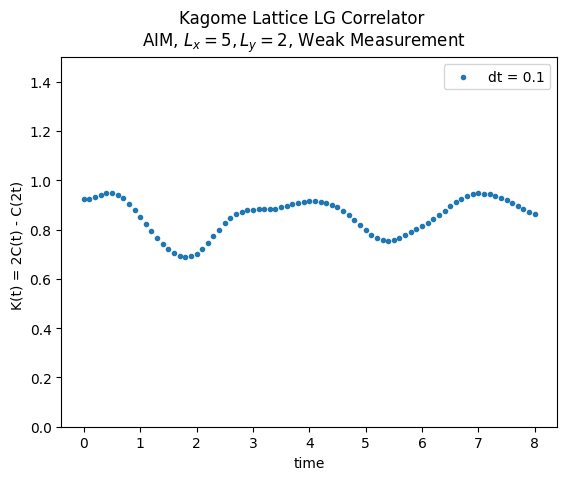

In [11]:
fig, ax = plt.subplots(1)
chi = 6000

times, LG_b, Kt = np.load('..\\data\\LG_data\\Lx5Ly2_U1.0_V0.32_chi6000_tebdChi500_cut100.0x1e_10_LGdata.npy', allow_pickle= True)
ax.scatter(times, Kt, marker = '.', label= "dt = 0.1" , zorder= 3)

times, LG_b, Kt =np.load('..\\data\\LG_data\\Lx5Ly2_U1.0_V0.32_chi6000_tebdChi500_cut100.0x1e_10_LGdata_dt_0_01.npy', allow_pickle= True)
#ax.scatter(times, Kt, marker = '.', label= "dt = 0.01" , zorder= 3)


fig.suptitle("Kagome Lattice LG Correlator\n AIM, $L_x = 5, L_y = 2$, Weak Measurement")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("time")
ax.set(ylabel = "K(t) = 2C(t) - C(2t) ")
ax.set_ylim([0,1.5])
plt.legend()

plt.show()

[['Sz', 'Sz', 'Sz', 'Sz']]
first 3.0636648000072455  second 11.304617699992377


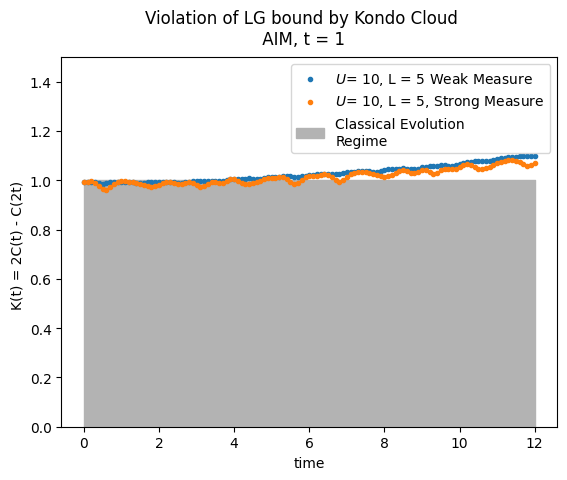

In [50]:

fig, ax = plt.subplots(1)

lg_options['trichotomic'] = False
lg_options['op1'] = 'Sz'
lg_options['phi_t_chi'] =  200
lg_options['scalar_product'] = 4
start1 = time.perf_counter()
times, LG_b, Kt = psi.calculate_LG_correlator(lg_options)  
ax.scatter(times, Kt, marker = '.', label= "$ U$= " + str(U) + ", L = " + str(L) + " Weak Measure" , zorder= 3)
end1 = time.perf_counter()

start2 = time.perf_counter()
lg_options['phi_t_chi'] = 200
lg_options['trichotomic'] = True
lg_options['scalar_product'] = 16
lg_options['op1'] = [['Sz'] * 4]
times, LG_b, Kt = psi.calculate_LG_correlator(lg_options)  
ax.scatter(times, Kt, marker = '.', label= "$ U$= " + str(U) + ", L = " + str(L) + ", Strong Measure" , zorder= 3)
end2 = time.perf_counter()


#times, LG_b, Kt = psi.calculate_LG_correlator([['Sz', 'Sz', 'Sz', 'Sz'] ], op_sum = False, site = 0, scalar_product = 16., trichotomic=True)
#ax.scatter(times, Kt, marker = '.', label= "$\\Gamma / U$= " + str(round(V ** 2,2)) + ", L = 10, Classical Correlator" , zorder= 3)


ax.fill_between(times,-3, 1 ,  color = '.7', label = "Classical Evolution\nRegime"  )

fig.suptitle("Violation of LG bound by Kondo Cloud\n AIM, t = 1")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("time")
ax.set(ylabel = "K(t) = 2C(t) - C(2t) ")
ax.set_ylim([0,1.5])
plt.legend()

print('first',end1 - start1, ' second', end2 - start2)
plt.show()

In [ ]:
fig.savefig("C:\\Users\\ianro\\Documents\\Research\\Quantum_Metrology_AKLT\\Plots\\AIM\\AIM_L10_50_K.png")

In [5]:
L = 5
lx = 2
ly = 2
t = 1.
V = 1/np.sqrt(10)
U = 10
mu = -.5 * U
lattice = 'Chain'
model_type = "AIM_Chain"

start = time.perf_counter()

extra_params = {
    'mixer': True,  # setting this to True helps to escape local minima
    'mixer_params' : 
        {'amplitude' : 1e-5,
        'decay' : 2,
        'disable_after' : 40},
    'max_E_err': 1.e-11,
    'max_sweeps'  : 1000,
    'max_trunc_err' : 1e-4,
    'trunc_params': 
        {'chi_max': 6000,
        'trunc_cut': 1e-10},
    'verbose': False,
    'method': 'SVD',
    'N_times' : 6,
    'dt': .1,'N_steps': 1,
    'order': 2, 'start_time' : 0,
    't_max' : 6  #only an option for calculating the maximum of the LG correlator
    }

model_params = {
    'mu' : 0, 'U': U, 'V' : V, 'J' : 1.0, 'mu_d' : mu,
    't' : t,
    'Lx': lx,
    'Ly' : ly,
    'L' : L,
    'h' : 0,
    'Jei' : 1,
    'Jii' : 1,
    'bc': 'finite',
    'model_type' : model_type,
    'cons_N' : 'N',
    'cons_Sz' : 'Sz',
    'target_Sz' : 0,
    'lattice' : lattice}

lg_options = {
    'op1' : 'Sz', 
    'op2' : None, 
    'op_sum' : True, 
    'site' : [0,2], 
    'calc_upto_2t' : True , 
    'scalar_product' : 4, 
    'verbose' : False,
    'trichotomic' : False,
    'phi_chi' : None, 
    'phi_t_chi': 200}

psi = State_Evo.from_dmrg(model_params, extra_params)
psi.calculate_QtQ(lg_options)


([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, -100, 0.8, -100, 1.0, -100, 1.2],
 [np.float64(1.5005372604621408),
  np.float64(1.4809101987218585),
  np.float64(1.423896270863247),
  np.float64(1.3348573647203326),
  np.float64(1.2219786956994603),
  np.float64(1.0952965429043502),
  np.float64(0.9655992118666747),
  -100,
  np.float64(0.7379039001357348),
  -100,
  np.float64(0.604718368731206),
  -100,
  np.float64(0.5968026440233147)])

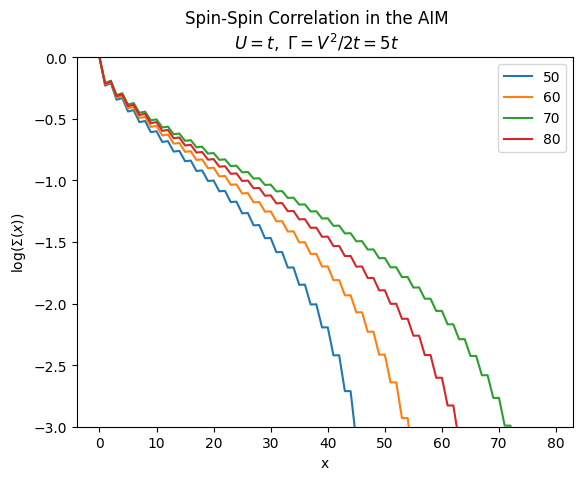

In [ ]:
SS_100, ISS_1, ntot_all, Sz_all = np.load("..\\data\\L50_Fermi_lowF.npy", allow_pickle = True)
SS_200, ISS_2, ntot_all, Sz_all = np.load("..\\data\\L60_Fermi_lowF.npy", allow_pickle = True)
SS_300, ISS_3, ntot_all, Sz_all = np.load("..\\data\\L70_Fermi_lowF.npy", allow_pickle = True)
SS_400, ISS_4, ntot_all, Sz_all = np.load("..\\data\\L80_Fermi_lowF.npy", allow_pickle = True)

SS_200 = np.abs(SS_200[0])
SS_300 = np.abs(SS_300[0])
SS_400 = np.abs(SS_400[0])
SS_100 = np.abs(SS_100[0])

fig, ax = plt.subplots(1)

Kondo_Length = vF /np.sqrt(U * Gamma/ 2) * np.exp(np.pi * np.abs((U + mu)* mu/(2 * U * Gamma)))
print(Kondo_Length, Gamma)

ax.plot(np.log(ISS_1), label="50")
ax.plot(np.log(ISS_2), label="60")
ax.plot(np.log(ISS_4), label="70")
ax.plot(np.log(ISS_3), label="80")

fig.suptitle("Spin-Spin Correlation in the AIM\n$ U = t,~ \\Gamma = V^2/2t = 5t$")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("x")
ax.set(ylabel = "$\\log(\\Sigma(x))$")
plt.ylim((-3,0))
plt.legend()

plt.show()

In [6]:
fig.savefig("C:\\Users\\ianro\\Documents\\Research\\Quantum_Metrology_AKLT\\Plots\\AIM\\AIM_L150_chi_correlation_length.png")

[(0, 1, array([0, 0])), (0, 2, array([0, 0])), (1, 2, array([0, 0])), (1, 0, array([1, 0])), (2, 0, array([0, 1])), (2, 1, array([-1,  1]))]


np.float64(3.0)

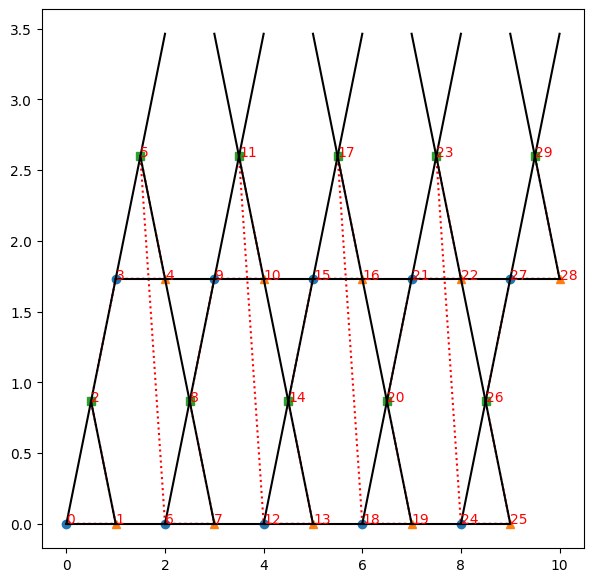

In [36]:
from tenpy.networks.site import FermionSite
lit = Kagome(5, 2, FermionSite , bc = ['open', 'periodic'])

fig, ax = plt.subplots(figsize=(7, 7))
lit.plot_sites(ax)
lit.plot_order(ax, linestyle=':')
lit.plot_coupling(ax, lit.pairs['nearest_neighbors'])
print(lit.pairs['nearest_neighbors'])
lit.distance(0,1, np.array([1,0]))

In [40]:
psi = tls.load_state('..\\data\\psi_data\\Lx1Ly2_U1.0_V0.32_chi6000_cut100.0x1e_10_Kagome.pkl')
phi = psi.apply_Q_MPO('Sz', site = 0, op_sum = 0)
q2 = phi.overlap(phi)
q = np.real(phi.overlap(psi))
qhq = psi.model.H_MPO.expectation_value(phi) * q2
h = psi.model.H_MPO.expectation_value(psi)
hpsi = psi.copy()
psi.model.H_MPO.apply(hpsi,options={'compression_method' : 'SVD', 'trunc_params': {
            'chi_max': 3000,
            'svd_min': 1e-9}})
qh_hq = 2 * np.real(phi.overlap(hpsi))


print(np.pi/3/(1/(q2 - q**2) * (qhq + q * h - qh_hq * q)- h))

1.7833512771597675


Nearest Neighbors:  [(0, 0, array([1, 0])), (0, 0, array([0, 1]))]


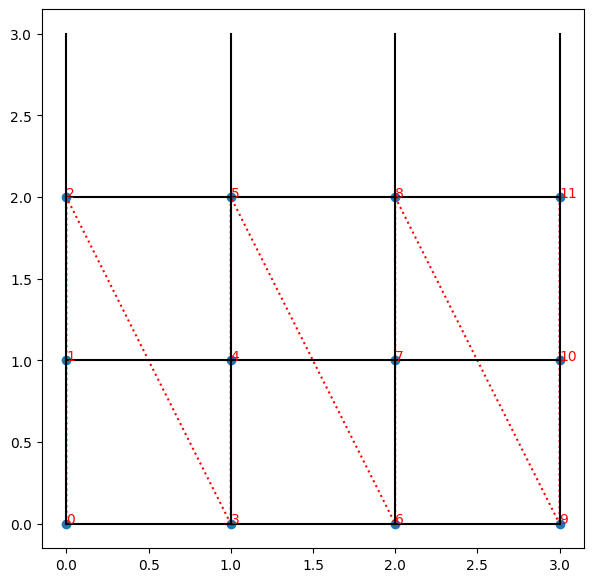

In [67]:
psi1 = tls.load_state("..\\data\\psi_data\\Lx4Ly3_Jii0.0_Jei0.3_h1.0em7_chi6000_cut100.0x1em10_Square.pkl")

lg_options = {
    'op1' : 'Szi', 
    'op2' : None, 
    'op_sum' : False, 
    'site' : 0, 
    'calc_upto_2t' : True , 
    'scalar_product' : 4, 
    'verbose' : False,
    'trichotomic' : False,
    'phi_chi' : None, 
    'phi_t_chi': 200}

extra_params = {
    'mixer': True,  # setting this to True helps to escape local minima
    'mixer_params' : 
        {'amplitude' : 1e-5,
        'decay' : 2,
        'disable_after' : 40},
    'max_E_err': 1.e-11,
    'max_sweeps'  : 1000,
    'max_trunc_err' : 1e-4,
    'trunc_params': 
        {'chi_max': 600,
        'trunc_cut': 1e-10},
    'verbose': False,
    'method': 'SVD',
    'N_times' : 2,
    'dt': .01,'N_steps': 1,
    'order': 2, 'start_time' : 0,
    't_max' : 6  #only an option for calculating the maximum of the LG correlator
    }

plot_lattice(psi1.model.lat)

In [ ]:
E_prime = []
Overlap = []
E_entropy = []
qfi_e =[]
qfi_i = []
qfi_ie = []
psi1 = tls.load_state("..\\data\\psi_data\\Lx4Ly3_Jii0.0_Jei0.25_h1.0em7_chi6000_cut100.0x1em10_Square.pkl")
xlist = np.arange(0.3, 1.0, 0.05)
bar = tls.ProgressBar(min_value = xlist[0], max_value = xlist[-1])

weight_list = [(0.5 - (i % 2))* 2 if i <= (psi1.L - 3) else 0 for i in range(psi1.L)]

for i in xlist:
    psi2 = tls.load_state("..\\data\\psi_data\\Lx4Ly3_Jii0.0_Jei"+str(np.round(i,2))+"_h1.0em7_chi6000_cut100.0x1em10_Square.pkl")
    #E_prime += [(psi2.energy - psi1.energy)/0.05]
    #Overlap += [-2.0 * np.log(np.abs(psi1.overlap(psi2)))/(0.05)**2]
    #E_entropy += [psi1.entanglement_entropy()[4]]
    #qfi_e += [psi1.QFI('Sze', scalar_multiply = weight_list)]
    qfi_i += [psi1.QFI('Szi',  scalar_multiply = weight_list)]
    #qfi_ie += [psi1.QFI('Sze Szi',  scalar_multiply = weight_list)]

    psi1 = psi2.copy()
    bar.update(i)

del psi1
del psi2

 [==================>.....................]  46.15% 

In [20]:
 [(0.5 - (i % 2))* 2 if i <= 9  else 0 for i in range(12)]

[1.0, -1.0, 1.0, -1.0, 1.0, -1.0, 1.0, -1.0, 1.0, -1.0, 0, 0]

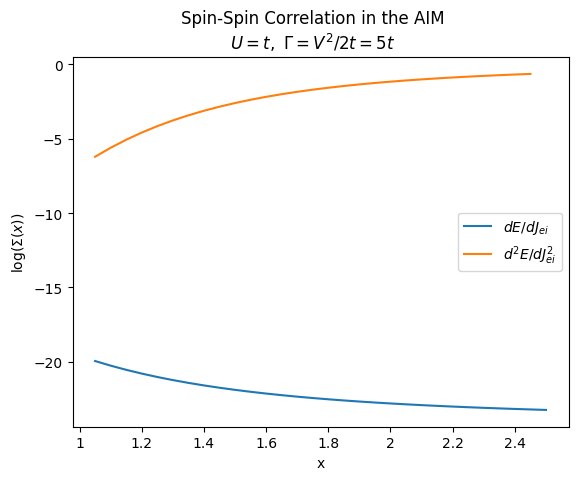

In [70]:
fig, ax = plt.subplots(1)

E_pprime = []
for i in range(1, len(E_prime)):
    E_pprime += [(E_prime[i] - E_prime[i-1])/0.05]

ax.plot(xlist[:len(E_prime)], E_prime, label = '$dE/dJ_{ei}$')
ax.plot(xlist[:len(E_prime)-1], E_pprime, label = '$d^2E/dJ_{ei}^2$')



fig.suptitle("Spin-Spin Correlation in the AIM\n$ U = t,~ \\Gamma = V^2/2t = 5t$")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("x")
ax.set(ylabel = "$\\log(\\Sigma(x))$")
#plt.ylim((-3,0))
plt.legend()

plt.show()

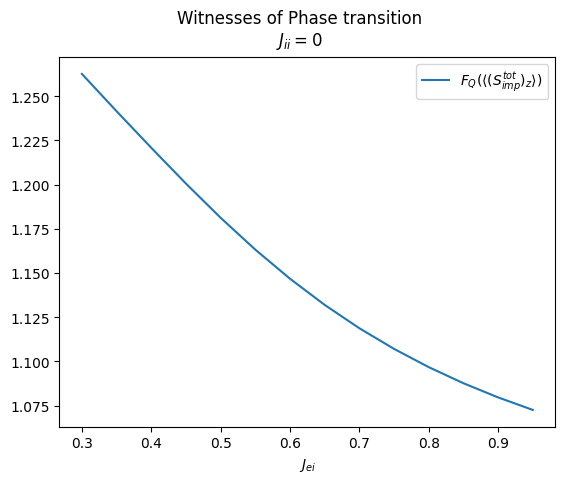

In [18]:
fig, ax = plt.subplots(1)

#ax.plot(xlist, qfi_e, label = '$F_Q(\\langle (S_{cond}^{tot})_z \\rangle$)')
ax.plot(xlist, qfi_i, label = '$F_Q(\\langle (S_{imp}^{tot})_z \\rangle$)')
#ax.plot(xlist, qfi_ie, label = '$F_Q(\\langle (S_{cond}^z \\times S_{imp}^z)_{tot} \\rangle$)')

fig.suptitle("Witnesses of Phase transition\n$ J_{ii} = 0$")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("$J_{ei}$")
#ax.set(ylabel = "$\\log(\\Sigma(x))$")
#plt.ylim((-3,0))
plt.legend()

plt.show()

In [58]:
.08 * 8

0.64

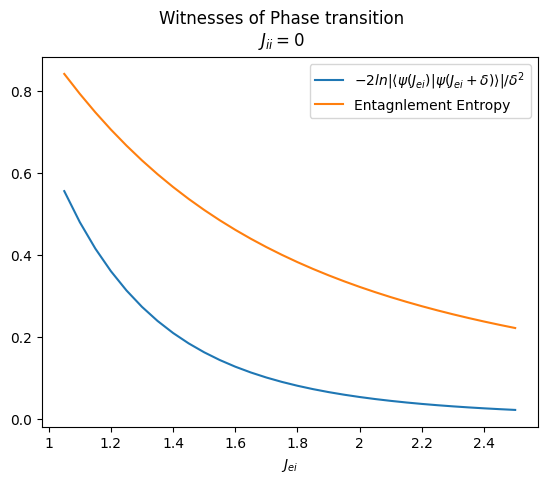

In [73]:
fig, ax = plt.subplots(1)

ax.plot(xlist, Overlap, label = '$-2 ln|\\langle\\psi(J_{ei})| \\psi(J_{ei}+\\delta)\\rangle|/\\delta^2$')
ax.plot(xlist, E_entropy, label = 'Entagnlement Entropy')

fig.suptitle("Witnesses of Phase transition\n$ J_{ii} = 0$")
ax.xaxis.set_major_formatter(tck.FormatStrFormatter("%g"))
plt.xlabel("$J_{ei}$")
#ax.set(ylabel = "$\\log(\\Sigma(x))$")
#plt.ylim((-3,0))
plt.legend()

plt.show()